In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time

In [2]:
#### CONSTANTES FÍSICAS 
## Vamos a trabajar en años
# T12 = 5730.0
# Lambda = np.log(2)/T12

T12 = np.log(2)
Lambda = np.log(2) / T12

n0 = 5*10**3 # número de núcleos a tiempo t=0

t = 5       # tiempo total que vamos a simular
dt = 0.05    # intervalo de tiempo
u = int(t/dt)  # número de intervalos
tiempos = np.arange(u + 1) * dt


# Posición del tiempo de vida media
pos_t12 = int(round(T12 / dt))

# Tiempo de referencia
t_ref = pos_t12 * dt

num_simulaciones = 500


In [3]:
inicio = time.perf_counter()

M = np.zeros((num_simulaciones, u + 1))

q_step = np.exp(-Lambda * dt)

t_estimado = np.zeros(len(M))

tiempo_suma = 0

for i in range(num_simulaciones):
    N = n0
    M[i, 0] = N

    for j in range(1, u + 1):
        N = np.random.binomial(N, q_step)
        M[i, j] = N

    t_estimado[i] = -1/Lambda * np.log(M[i, pos_t12] / n0)
    tiempo_suma += t_estimado[i]

fin = time.perf_counter()

np.savetxt("Tiempo_estimado_para_cada_número_de_núcleos.txt", t_estimado)

tiempo_estimado = tiempo_suma / num_simulaciones
sigma_muestral = np.std(t_estimado, ddof=1)
sigma_muestral_relativo = sigma_muestral / tiempo_estimado

sigma_teórico = 1 / Lambda * np.sqrt((np.exp(t_ref * Lambda)-1) / n0)
sigma_teórico_relativo = sigma_teórico / t_ref

print(f"Tiempo de ejecución: {fin - inicio} segundos")
print(f"Tiempo de vida media de referencia: {t_ref} +- {sigma_teórico} años")
print(f"Tiempo estimado: {tiempo_estimado} +- {sigma_muestral} años")
print(f"Sigma teórico relativo: {sigma_teórico_relativo}")
print(f"Sigma muestral relativo: {sigma_muestral_relativo}")



Tiempo de ejecución: 0.08520264499929908 segundos
Tiempo de vida media de referencia: 0.7000000000000001 +- 0.014239049880314884 años
Tiempo estimado: 0.6998932498195518 +- 0.01409988665961811 años
Sigma teórico relativo: 0.02034149982902126
Sigma muestral relativo: 0.02014576746275718


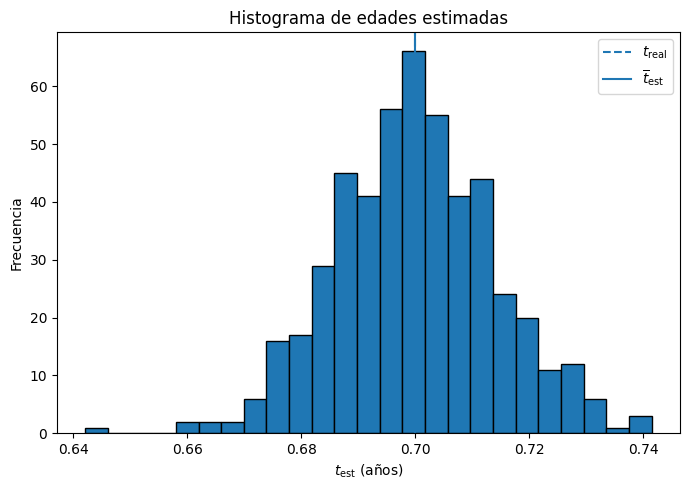

In [4]:
plt.figure(figsize=(7, 5))
plt.hist(t_estimado, bins=25, edgecolor="black")

plt.axvline(t_ref, linestyle="--", label=r"$t_{\mathrm{real}}$")
plt.axvline(tiempo_estimado, linestyle="-", label=r"$\overline{t}_{\mathrm{est}}$")

plt.xlabel(r"$t_{\mathrm{est}}$ (años)")
plt.ylabel("Frecuencia")
plt.title("Histograma de edades estimadas")
plt.legend()
plt.tight_layout()
plt.savefig("histograma_tiempo_estimado.png", dpi=300)
plt.show()